Cell 1 – Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

Cell 2 – Upload dataset

In [2]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Saving Wholesale customers data.csv to Wholesale customers data (1).csv
Dataset loaded successfully!
Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


Cell 3 – Understand the dataset

In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Statistical Summary:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000



Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate Records:
0


Cell 4 – Data cleaning and feature selection

In [4]:
df = df.drop_duplicates()

features = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicassen'
]

X = df[features].copy()

X = X.fillna(X.median())

print("Selected Features:")
display(X.head())

Selected Features:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Cell 5 – Exploratory Data Analysis

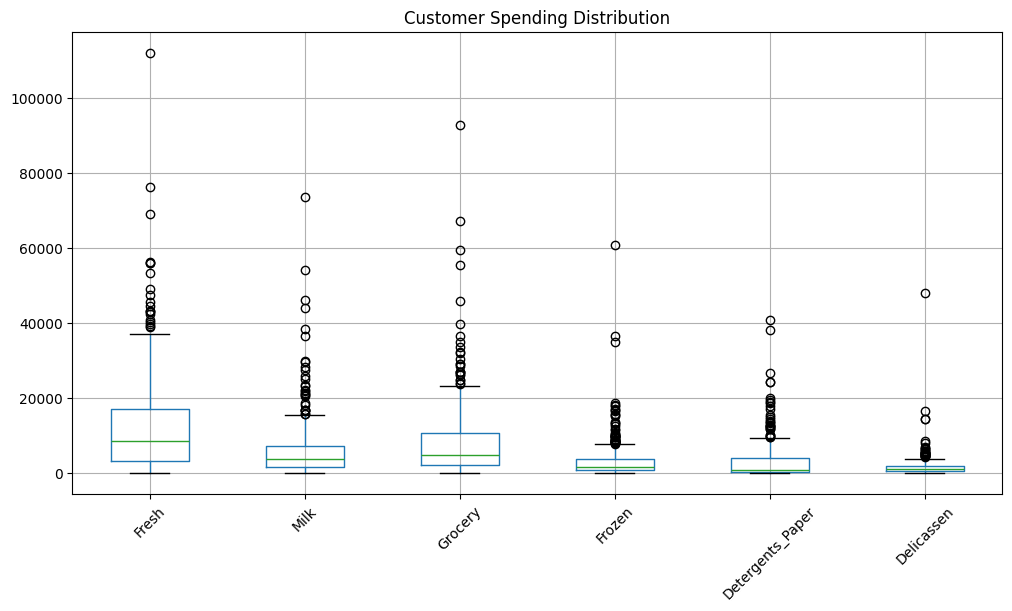

In [5]:
plt.figure(figsize=(12,6))

df[features].boxplot()

plt.title('Customer Spending Distribution')
plt.xticks(rotation=45)
plt.show()

Cell 6 – Log transformation and StandardScaler

In [6]:
X_log = np.log1p(X)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

print("Standardized data:")
print(X_scaled[:5])

Standardized data:
[[ 0.4861845   0.97629884  0.44015468 -1.50924981  0.64414327  0.40896595]
 [ 0.08788863  0.99095612  0.65217085  0.13405226  0.76604314  0.62792606]
 [ 0.01635628  0.89115098  0.45468702  0.37689926  0.80440496  1.77683339]
 [ 0.51747725 -0.95797283 -0.08479166  1.14157433 -0.3287115   0.63313326]
 [ 0.8806309   0.43966195  0.39584651  0.75732216  0.40493851  1.4565879 ]]


Cell 7 – Apply PCA

In [7]:
pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_scaled)

print("Original Features:", X_scaled.shape[1])
print("PCA Components:", X_pca.shape[1])

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Explained Variance:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

Original Features: 6
PCA Components: 5
Explained Variance Ratio:
[0.44077752 0.27194917 0.10698428 0.10103287 0.04876269]
Total Explained Variance: 96.95 %


Cell 8 – Find the suitable number of clusters

In [8]:
scores = []

for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_pca)

    score = silhouette_score(X_pca, labels)

    scores.append(score)

    print("Clusters:", k, "Silhouette Score:", round(score, 3))

best_k = range(2, 7)[np.argmax(scores)]

print("\nBest number of clusters:", best_k)

Clusters: 2 Silhouette Score: 0.3
Clusters: 3 Silhouette Score: 0.27
Clusters: 4 Silhouette Score: 0.198
Clusters: 5 Silhouette Score: 0.201
Clusters: 6 Silhouette Score: 0.203

Best number of clusters: 2


Cell 9 – Build the K-Means model

In [9]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_pca)

df['Cluster'] = clusters

print("Clustering completed!")
display(df.head())

Clustering completed!


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,0
1,2,3,7057,9810,9568,1762,3293,1776,0
2,2,3,6353,8808,7684,2405,3516,7844,0
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,0


Cell 10 – PCA visualization

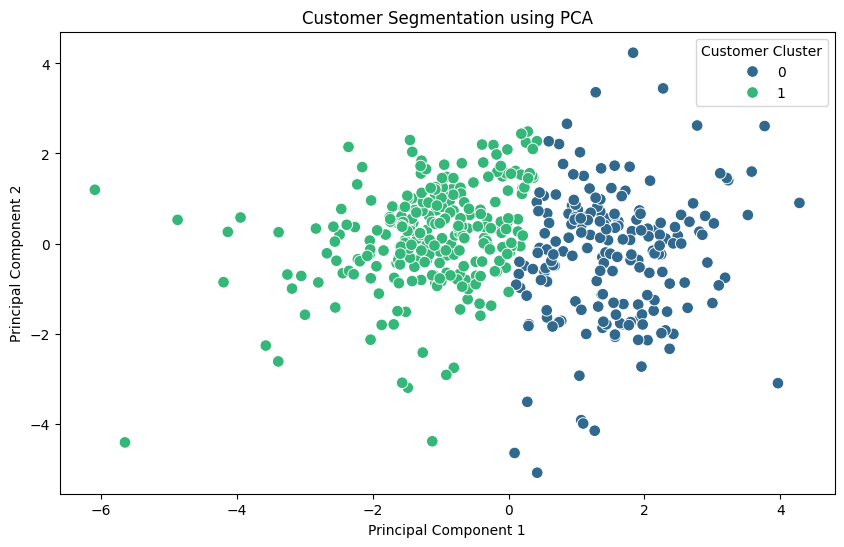

In [10]:
pca_2d = PCA(n_components=2)

X_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(10,6))

sns.scatterplot(
    x=X_2d[:, 0],
    y=X_2d[:, 1],
    hue=df['Cluster'],
    palette='viridis',
    s=70
)

plt.title('Customer Segmentation using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Customer Cluster')

plt.show()

Cell 11 – Evaluate the model

In [11]:
final_score = silhouette_score(X_pca, clusters)

print("Silhouette Score:",
      round(final_score, 3))

print("Explained Variance:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

Silhouette Score: 0.3
Explained Variance: 96.95 %


Cell 12 – Analyse customer groups

In [12]:
cluster_summary = df.groupby('Cluster')[features].mean().round(2)

display(cluster_summary)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43
1,13973.13,2401.75,2918.71,3705.67,491.94,1038.04


Cell 13 – Save results

In [13]:
df.to_csv(
    'PCA_Customer_Segmentation_Results.csv',
    index=False
)

print("Results saved successfully!")

files.download('PCA_Customer_Segmentation_Results.csv')

Results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>